# 04 – Calendar features: what we know about the future in advance

So far we wrote forecasting **rules** by hand. From step 7 on, a **model** will learn the rules itself.
But a model only sees columns of numbers. It can't look at "2017-08-31" and know that it is a Thursday,
a payday, and not a holiday. **Features** turn that knowledge into columns.

Calendar features have a special property: **we know them in advance.** On 15 August we already know
the weekday of 31 August and which holidays are coming. So they can't leak the future
(unlike features built from past sales, which need care, in step 6).

**Plan:**
1. A way to measure a calendar effect without a model.
2. The payday cycle.
3. Holidays: the three traps in the holidays file, and how big each kind of holiday is.
4. What the features say about the Kaggle test period.
5. Tests for the feature code.

The feature code lives in `src/features.py`; this notebook explains and checks it.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_test, load_train
from src.features import calendar_features, holiday_features, load_holidays, load_stores

IMAGES = "../images"

train = load_train()
stores = load_stores()
holidays = load_holidays()

## 1. Measuring a calendar effect without a model

Question: "do stores sell more on paydays?" Comparing paydays with the overall average would mislead,
because sales also depend on the weekday, the season, and the trend.

A fairer comparison: compare each day with **the same weekday in the 4 weeks before and the 4 weeks after**.
That "normal" level has the same weekday and almost the same season and trend, so what's left is mostly the
effect of that specific day.

We do this per store (total sales of the store), giving a **ratio**: 1.20 means "20% above normal".

*Important:* looking at the weeks **after** a day is fine here, because we are **describing the past**, not
forecasting. A forecasting feature could never do this. Knowing which situation you are in is half of avoiding leakage.

In [2]:
# Total sales per store and day, on a complete calendar (the missing Christmas days become NaN).
store_sales = train.groupby(["date", "store_nbr"], observed=True)["sales"].sum().unstack()
store_sales = store_sales.reindex(pd.date_range(store_sales.index.min(), store_sales.index.max(), name="date"))

# Days with zero sales (store closed or not yet open) would distort the comparison: treat them as unknown.
store_sales = store_sales.where(store_sales > 0)

# "Normal" = average of the same weekday 1-4 weeks before and 1-4 weeks after.
# shift(7) moves the table down by 7 rows (= one week back), shift(-7) one week forward.
neighbours = [store_sales.shift(7 * k) for k in [-4, -3, -2, -1, 1, 2, 3, 4]]
normal = pd.concat(neighbours).groupby(level=0).mean()

ratio = (store_sales / normal).stack().rename("ratio").reset_index()  # long: one row per (date, store)
print(f"{len(ratio):,} store-days, median ratio {ratio['ratio'].median():.3f}")

91,152 store-days, median ratio 0.975


The median is a bit below 1 (0.97) because a few very high days, like before Christmas, raise the
"normal" level of the days around them. Keep that in mind: an effect is real when it clearly differs from about 0.97, not from 1.

We use the **median** rather than the mean throughout: a few extreme days (the earthquake, store openings)
would pull a mean around, while the median shows the typical day.

## 2. The payday cycle

Notebook 01 hinted at a payday effect in one series. Now we check it across all stores, and compare two
ways to describe it: **day of the month**, and **days since the last payday** (the 15th and the last day
of the month are paydays for public-sector workers).

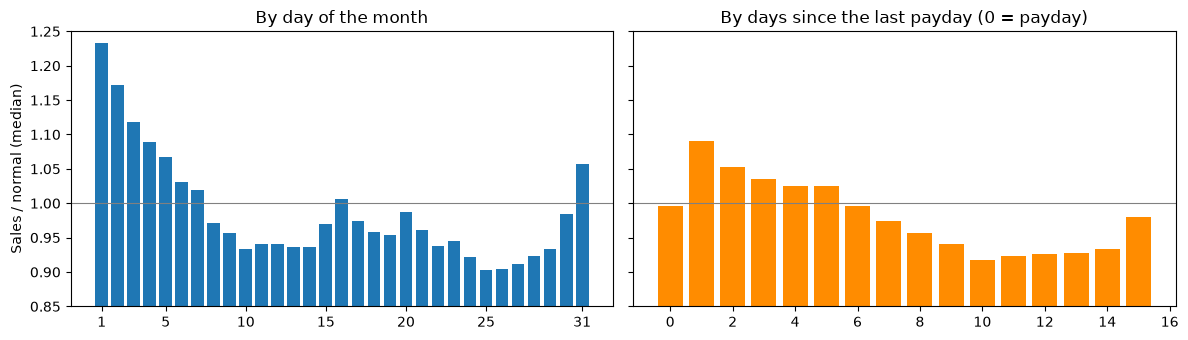

Day of month 1, 16, 25, 31: [1.232, 1.005, 0.903, 1.058]


In [3]:
calendar = calendar_features(ratio["date"].unique())
with_calendar = ratio.merge(calendar, left_on="date", right_index=True)

by_day = with_calendar.groupby("day_of_month")["ratio"].median()
by_payday = with_calendar.groupby("days_since_payday")["ratio"].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
axes[0].bar(by_day.index, by_day)
axes[0].set_title("By day of the month")
axes[0].set_xticks([1, 5, 10, 15, 20, 25, 31])
axes[1].bar(by_payday.index, by_payday, color="darkorange")
axes[1].set_title("By days since the last payday (0 = payday)")
for ax in axes:
    ax.axhline(1, color="grey", linewidth=0.8)
    ax.set_ylim(0.85, 1.25)
axes[0].set_ylabel("Sales / normal (median)")
fig.tight_layout()
fig.savefig(f"{IMAGES}/payday_cycle.png", dpi=120)
plt.show()

print("Day of month 1, 16, 25, 31:", by_day.loc[[1, 16, 25, 31]].round(3).tolist())

**What we found:** a clear monthly cycle. The 1st sells about 23% above normal, then sales fall day by day to
about 10% below normal around the 25th, and rise again on the last day of the month (+6%).
The mid-month payday gives only a small bump (the 16th is about normal, against about 0.93 on the 10th–14th).

So the two paydays are **not equal**: the end-of-month payday matters much more. That's useful to know when
choosing features:
- `days_since_payday` treats both paydays the same, which is too simple here.
- `day_of_month` can capture the difference.

We keep **both** columns: a tree model like LightGBM can use whichever helps, and it costs us nothing.

## 3. Holidays

### The three traps in the holidays file

In [4]:
holidays[holidays["date"].between("2017-08-01", "2017-08-31")]

,date,type,locale,locale_name,description,transferred
323,2017-08-05,Holiday,Local,Esmeraldas,Fundacion de Esmeraldas,False
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
325,2017-08-11,Transfer,National,Ecuador,Traslado Primer Grito de Independencia,False
326,2017-08-15,Holiday,Local,Riobamba,Fundacion de Riobamba,False
327,2017-08-24,Holiday,Local,Ambato,Fundacion de Ambato,False


This one month shows all three traps (read `holiday_features` in `src/features.py` for the code):

1. **Transferred holidays.** 10 August has `transferred=True`: the holiday was moved, and the next row
   ("Traslado", type `Transfer`) shows its new date, 11 August. On 10 August people worked normally.
   Counting 10 August as a holiday would teach the model a wrong pattern.
2. **Locale.** "Fundacion de Ambato" is a **local** holiday: only stores in Ambato are affected,
   not all 54. Same for regional holidays and the store's state.
3. **Types.** `Additional` days (around Christmas), `Bridge` days (an extra day off between a holiday
   and a weekend), `Work Day` (a Saturday made a working day to make up for a bridge), and `Event`
   (Mother's Day, Black Friday, the 2016 earthquake...). They behave differently, so each gets its own column.

In [5]:
holiday_flags = holiday_features(store_sales.index, stores, holidays)
holiday_flags.sum().rename("store-days flagged")

national_day_off       2916
national_additional    1566
national_work_day       270
national_event         1350
earthquake             1674
regional_holiday         31
local_holiday           360
Name: store-days flagged, dtype: int64

### How big is each kind of special day?

Same measurement as for paydays: the median ratio to normal, on the days each flag marks.

In [6]:
with_holidays = ratio.merge(holiday_flags.reset_index(), on=["date", "store_nbr"])

effects = pd.DataFrame({
    column: {
        "store-days": int(with_holidays[column].sum()),
        "median ratio": with_holidays.loc[with_holidays[column] == 1, "ratio"].median(),
    }
    for column in holiday_flags.columns
}).T
effects.loc["(normal day)"] = [len(with_holidays), with_holidays["ratio"].median()]
effects.round(3)

,store-days,median ratio
national_day_off,2916.0,1.079
national_additional,1566.0,1.261
national_work_day,270.0,0.969
national_event,1350.0,0.877
earthquake,1674.0,0.996
regional_holiday,31.0,1.147
local_holiday,360.0,0.964
(normal day),91152.0,0.975


**What we found:**
- **National `Additional` days** (mostly the days before Christmas and New Year): about **+26%** above a typical day.
  This is the biggest regular holiday effect.
- **National days off: about +8%** at the median, smaller than you might expect. Some holidays raise sales,
  others lower them (people travel or stay home), so they partly cancel out. A model could learn the difference
  per holiday, but with only 4–5 years of each holiday that is hard.
- **National events** (Mother's Day, Black Friday, football matches...) are about **10% below** normal.
  We haven't checked why; it could be that these weekends are compared with busier ones, or that people
  shop less while watching a match. The flag lets the model use it either way.
- **Regional holidays** about +15%, but from few store-days, so this is uncertain.
- **Local holidays: no clear effect** (about the same as a normal day).
- **The earthquake** has a median close to normal over its 31 days: the huge spike in notebook 01 was in
  grocery families of some stores in the first days. The median over all stores and the whole month hides it.
  A flag still helps the model treat that period as special.

*How much to trust these numbers?* They are medians over many store-days, but each holiday type contains
only a handful of distinct dates. Treat them as "big / small / none", not as precise percentages.

## 4. What the features say about the Kaggle test period

The test is 16–31 August 2017. Which special days does it contain?

In [7]:
test = load_test()
test_dates = pd.DatetimeIndex(sorted(test["date"].unique()), name="date")

test_holidays = holiday_features(test_dates, stores, holidays)
flagged = test_holidays[test_holidays.sum(axis=1) > 0]
print(f"Store-days with any holiday flag in the test period: {len(flagged)} of {len(test_holidays)}")
flagged.loc[:, (flagged != 0).any()]

Store-days with any holiday flag in the test period: 2 of 864


local_holiday
date       store_nbr               
2017-08-24 23                     1
           50                     1

In [8]:
calendar_features(test_dates).T

date,2017-08-16,2017-08-17,2017-08-18,2017-08-19,2017-08-20,2017-08-21,2017-08-22,2017-08-23,2017-08-24,2017-08-25,2017-08-26,2017-08-27,2017-08-28,2017-08-29,2017-08-30,2017-08-31
day_of_week,2,3,4,5,6,0,1,2,3,4,5,6,0,1,2,3
day_of_month,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
month,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8
days_since_payday,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,0


**What we found:** the test period is almost holiday-free. No national holidays, only Ambato's local holiday
on 24 August (one store-day per Ambato store), and local holidays showed no clear effect anyway.

The **payday cycle**, however, runs through the whole test period: it starts the day after the mid-month payday,
falls towards the 25th–26th, and ends on the end-of-month payday (31 August). Our level + weekday rule from
step 4 ignores this: it forecasts the same level on the 25th as on the 31st.

So for the test period, **the payday cycle should matter more than the holidays.** Holiday features still matter
for **training**: without them, a model would see the Christmas spikes and the earthquake and try to explain
them with other columns, learning wrong patterns.

## 5. Tests for the feature code

Feature code is easy to get subtly wrong: an off-by-one on paydays, or a transferred holiday counted as a day off.
The model would still train, the score would just be a bit worse, and nobody would notice.

`tests/test_features.py` checks the rules we decided on, with tiny hand-made examples:
- `days_since_payday` is 0 on the 15th and on the last day of the month (also in February);
- a transferred holiday counts only on its new date;
- a local holiday only applies to stores in that city;
- one row per (date, store), no duplicates.

Run them from the project folder (in a terminal, with the `store-sales` environment active):

```bash
pytest
```

All 6 should pass. **A test is only useful if it can fail.** To check that, we temporarily removed the
transferred-holiday filter from `holiday_features`: the transferred-holiday test failed, and it passed again
once the line was back.

## Summary

| Finding | Feature |
|---|---|
| Sales +23% on the 1st, −10% around the 25th, +6% on the 31st | `day_of_month`, `days_since_payday` |
| The end-of-month payday matters more than the mid-month one | Keep both payday columns |
| Days around Christmas +26%, bridge days large | `national_additional`, `national_day_off` |
| Transferred holidays are normal days on their original date | Filtered out in `holiday_features` |
| Local holidays: no clear effect | `local_holiday` kept, but don't expect much |
| The test period has no national holidays, but a full payday cycle | Payday features should matter most there |

**Next step (step 6):** lag features, built from past sales. That's where leakage becomes a real danger:
with a 16-day horizon, every lag must be at least 16 days old.